# $p$ - primes


In [1]:
from sympy import isprime, nextprime, primerange

list(primerange(11, 20))

[11, 13, 17, 19]

In [2]:
ppp = [nextprime(1 << (n + 1)) for n in range(8)][::-1]
print(ppp)

[257, 131, 67, 37, 17, 11, 5, 3]


In [3]:
TEST_P_IDX = 4
TEST_P = ppp[TEST_P_IDX]
TEST_P_IDX, TEST_P

(4, 17)

# $V$ - Vandermonde matrices


In [4]:
import numpy as np

In [5]:
VVV = []
for p in ppp:
    VVV.append(np.array([[pow(x, j, p) for j in range(p - 1)] for x in range(1, p)]))
VVV

[array([[  1,   1,   1, ...,   1,   1,   1],
        [  1,   2,   4, ..., 225, 193, 129],
        [  1,   3,   9, ..., 238, 200,  86],
        ...,
        [  1, 254,   9, ...,  19, 200, 171],
        [  1, 255,   4, ...,  32, 193, 128],
        [  1, 256,   1, ..., 256,   1, 256]], shape=(256, 256)),
 array([[  1,   1,   1, ...,   1,   1,   1],
        [  1,   2,   4, ...,  82,  33,  66],
        [  1,   3,   9, ...,  34, 102,  44],
        ...,
        [  1, 128,   9, ...,  97, 102,  87],
        [  1, 129,   4, ...,  49,  33,  65],
        [  1, 130,   1, ..., 130,   1, 130]], shape=(130, 130)),
 array([[ 1,  1,  1, ...,  1,  1,  1],
        [ 1,  2,  4, ..., 42, 17, 34],
        [ 1,  3,  9, ...,  5, 15, 45],
        ...,
        [ 1, 64,  9, ..., 62, 15, 22],
        [ 1, 65,  4, ..., 25, 17, 33],
        [ 1, 66,  1, ..., 66,  1, 66]], shape=(66, 66)),
 array([[ 1,  1,  1, ...,  1,  1,  1],
        [ 1,  2,  4, ..., 14, 28, 19],
        [ 1,  3,  9, ..., 11, 33, 25],
        ...,

# $A$ - Analysis matrices


In [6]:
AAA = []

for p in ppp:
    AAA.append(
        np.array([[(-pow(a, -n, p)) % p for n in range(p - 1)] for a in range(1, p)])
    )

AAA

[array([[256, 256, 256, ..., 256, 256, 256],
        [256, 128,  64, ..., 249, 253, 255],
        [256, 171,  57, ..., 230, 248, 254],
        ...,
        [256,  86,  57, ...,  27, 248,   3],
        [256, 129,  64, ...,   8, 253,   2],
        [256,   1, 256, ...,   1, 256,   1]], shape=(256, 256)),
 array([[130, 130, 130, ..., 130, 130, 130],
        [130,  65,  98, ..., 123, 127, 129],
        [130,  87,  29, ..., 104, 122, 128],
        ...,
        [130,  44,  29, ...,  27, 122,   3],
        [130,  66,  98, ...,   8, 127,   2],
        [130,   1, 130, ...,   1, 130,   1]], shape=(130, 130)),
 array([[66, 66, 66, ..., 66, 66, 66],
        [66, 33, 50, ..., 59, 63, 65],
        [66, 22, 52, ..., 40, 58, 64],
        ...,
        [66, 45, 52, ..., 27, 58,  3],
        [66, 34, 50, ...,  8, 63,  2],
        [66,  1, 66, ...,  1, 66,  1]], shape=(66, 66)),
 array([[36, 36, 36, ..., 36, 36, 36],
        [36, 18,  9, ..., 29, 33, 35],
        [36, 12,  4, ..., 10, 28, 34],
        ...,

# Matrices Test


In [7]:
test_vector = np.array([pow(10, i, TEST_P) for i in range(TEST_P - 1)])
t = (AAA[TEST_P_IDX] @ test_vector) % TEST_P
print(t.shape)
t

(16,)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [8]:
test_vector = np.array([pow(10, i, TEST_P) for i in range(TEST_P - 1)]) * 10 % TEST_P
t = (AAA[TEST_P_IDX] @ test_vector) % TEST_P
print(t.shape)
t

(16,)


array([ 0,  0,  0,  0,  0,  0,  0,  0,  0, 10,  0,  0,  0,  0,  0,  0])

In [9]:
test_vector = (
    np.array([pow(2, i, TEST_P) for i in range(TEST_P - 1)]) * 99
    + np.array([pow(3, i, TEST_P) for i in range(TEST_P - 1)]) * 88
    + np.array([pow(4, i, TEST_P) for i in range(TEST_P - 1)]) * 77
    + np.array([pow(1, i, TEST_P) for i in range(TEST_P - 1)]) * 6
) % TEST_P
t = (AAA[TEST_P_IDX] @ test_vector) % TEST_P
print(t.shape)
t

(16,)


array([ 6, 14,  3,  9,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [10]:
np.array_equal(AAA[TEST_P_IDX] @ VVV[TEST_P_IDX].T % TEST_P, np.eye(TEST_P - 1))

True

In [11]:
np.array_equal(
    VVV[TEST_P_IDX].T @ (AAA[TEST_P_IDX] @ test_vector) % TEST_P,
    test_vector,
)

True

# Open an existing file


In [12]:
fs = open("Wildlife.wmv", "rb")
chunk = fs.read(ppp[0] - 1)
fs.close()

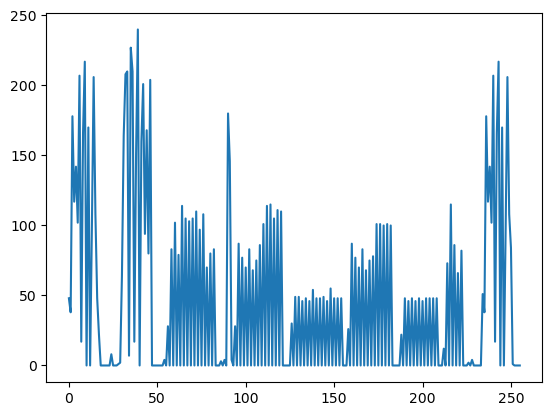

In [13]:
import matplotlib.pyplot as plt
plt.plot(list(chunk))

# Adaptivity Test

In [14]:
test_vector = np.array(list(chunk))
np.array_equal(
    VVV[0].T @ (AAA[0] @ test_vector) % ppp[0],
    test_vector,
)

True

In [15]:
test_vector = np.array(list(i & 0b_111_1111 for i in chunk[:ppp[1]-1]))
np.array_equal(
    VVV[1].T @ (AAA[1] @ test_vector) % ppp[1],
    test_vector,
)

True

In [16]:
test_vector = np.array(list(i & 0b_11_1111 for i in chunk[:ppp[2]-1]))
np.array_equal(
    VVV[2].T @ (AAA[2] @ test_vector) % ppp[2],
    test_vector,
)

True

In [17]:
test_vector = np.array(list(i & 0b_1_1111 for i in chunk[:ppp[3]-1]))
np.array_equal(
    VVV[3].T @ (AAA[3] @ test_vector) % ppp[3],
    test_vector,
)

True

# Bases Test